# 02 · Trees, ensembles (bagging vs boosting), SVM and KNN

| Model | Idea | Strength | Watch out |
|---|---|---|---|
| Decision tree | Split on the feature/threshold that most reduces impurity (Gini/entropy) | Interpretable, no scaling | Overfits when deep |
| Random forest | **Bagging**: many deep trees on bootstrap samples + random feature subsets; average | Strong default, low variance | Bigger, slower |
| Gradient boosting (XGBoost, LightGBM, HistGB) | **Boosting**: shallow trees added one by one, each fixing the previous errors | Best on tabular data | Tune learning rate / trees; can overfit |
| SVM | Maximise the margin; kernels for non-linear boundaries | Good on small/medium data | Needs scaling; slow on big n |
| KNN | Vote of the k nearest points | Simple baseline | Needs scaling; slow at prediction |

**Bagging reduces variance. Boosting reduces bias.**

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance, DecisionBoundaryDisplay

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

## 1. Tree depth: from underfit to overfit

max_depth=1     train 0.930  test 0.888  leaves 2
max_depth=3     train 0.977  test 0.916  leaves 8
max_depth=5     train 1.000  test 0.902  leaves 18
max_depth=None  train 1.000  test 0.902  leaves 18


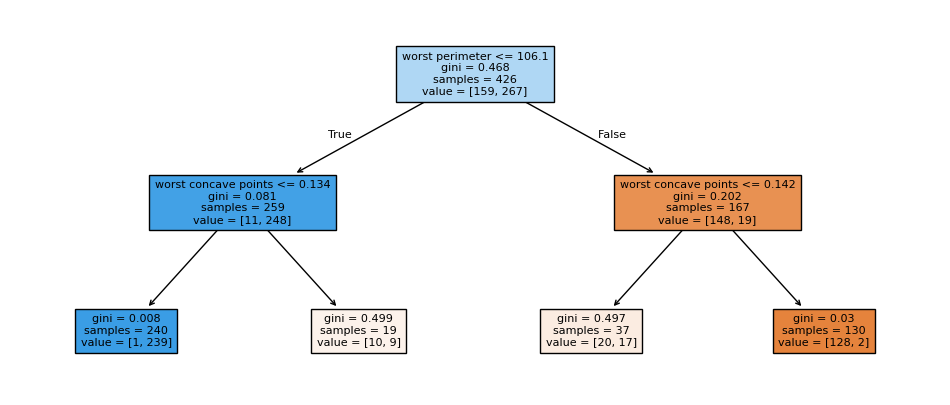

In [2]:
for depth in [1, 3, 5, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtr, ytr)
    print(f"max_depth={depth!s:5} train {t.score(Xtr, ytr):.3f}  test {t.score(Xte, yte):.3f}  leaves {t.get_n_leaves()}")
small = DecisionTreeClassifier(max_depth=2, random_state=0).fit(Xtr, ytr)
plt.figure(figsize=(12, 5)); plot_tree(small, feature_names=X.columns, filled=True, fontsize=8); plt.show()

## 2. Compare the families with the same CV

In [3]:
models = {
    "Decision tree": DecisionTreeClassifier(random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "Hist gradient boosting": HistGradientBoostingClassifier(random_state=0),
    "SVM (RBF) + scaling": make_pipeline(StandardScaler(), SVC()),
    "SVM (RBF) NO scaling": SVC(),
    "KNN + scaling": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "KNN NO scaling": KNeighborsClassifier(),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, Xtr, ytr, cv=cv)
    rows.append((name, s.mean(), s.std()))
pd.DataFrame(rows, columns=["model", "cv acc", "std"]).sort_values("cv acc", ascending=False).round(3)

,model,cv acc,std
3,SVM (RBF) + scaling,0.981,0.012
2,Hist gradient boosting,0.969,0.016
5,KNN + scaling,0.967,0.023
1,Random forest,0.962,0.009
6,KNN NO scaling,0.934,0.019
0,Decision tree,0.927,0.023
4,SVM (RBF) NO scaling,0.918,0.037


Note how much SVM and KNN lose without scaling: they depend on distances.

## 3. Random forest: out-of-bag (OOB) score is free validation
Each tree skips ~37% of rows (bootstrap). Those rows score the tree.

In [4]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
print("OOB accuracy:", round(rf.oob_score_, 3), "| test accuracy:", round(rf.score(Xte, yte), 3))

OOB accuracy: 0.962 | test accuracy: 0.944


## 4. Boosting: learning rate × number of trees, and early stopping

In [5]:
for lr in [0.3, 0.1, 0.03]:
    gb = HistGradientBoostingClassifier(learning_rate=lr, max_iter=1000, early_stopping=True,
                                        validation_fraction=0.15, n_iter_no_change=20, random_state=0).fit(Xtr, ytr)
    print(f"learning_rate={lr}: stopped at {gb.n_iter_} trees, test acc {gb.score(Xte, yte):.3f}")

learning_rate=0.3: stopped at 43 trees, test acc 0.951
learning_rate=0.1: stopped at 113 trees, test acc 0.958


learning_rate=0.03: stopped at 273 trees, test acc 0.958


## 5. Feature importance: impurity-based vs permutation
Impurity importance is biased toward high-cardinality features and is computed on training data.
**Permutation importance** on held-out data measures how much the score drops when a feature is shuffled.

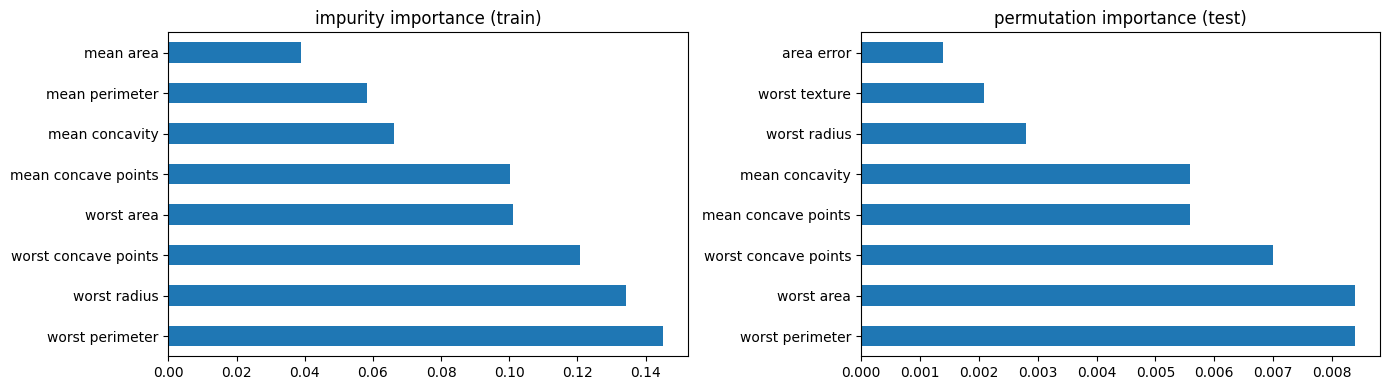

In [6]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
perm = permutation_importance(rf, Xte, yte, n_repeats=10, random_state=0)
perm_s = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(8)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
imp.plot.barh(ax=axes[0], title="impurity importance (train)"); perm_s.plot.barh(ax=axes[1], title="permutation importance (test)")
plt.tight_layout(); plt.show()

## 6. Decision boundaries on a non-linear toy problem

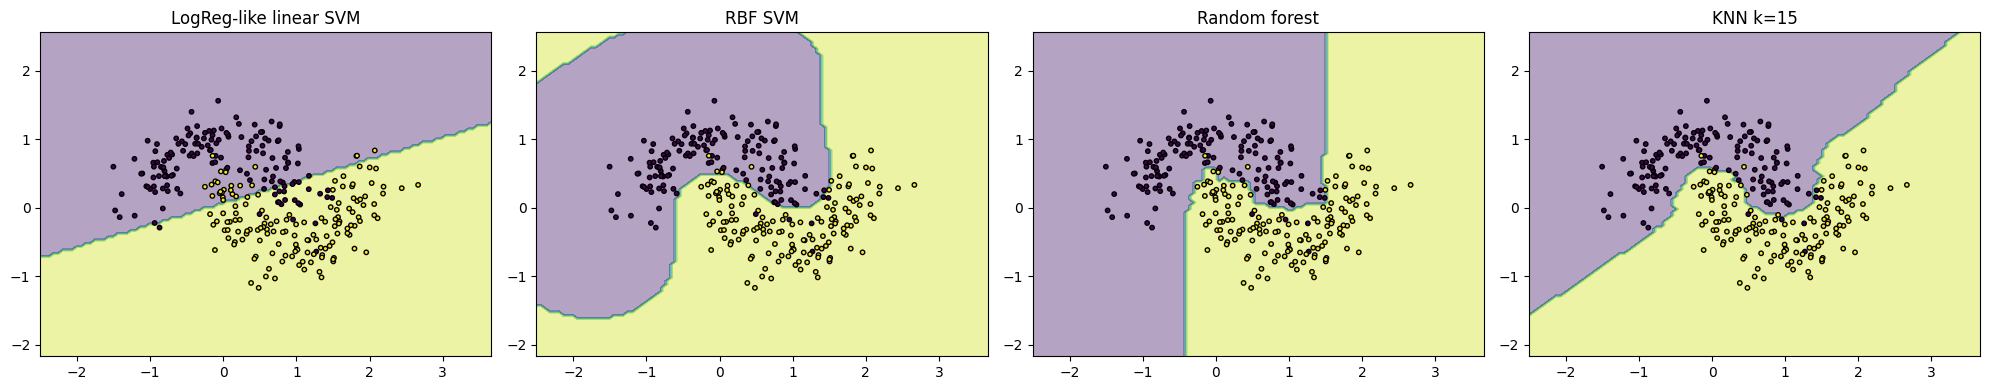

In [7]:
Xm, ym = make_moons(300, noise=0.25, random_state=0)
toy = {"LogReg-like linear SVM": make_pipeline(StandardScaler(), SVC(kernel="linear")),
       "RBF SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)),
       "Random forest": RandomForestClassifier(random_state=0),
       "KNN k=15": make_pipeline(StandardScaler(), KNeighborsClassifier(15))}
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, m) in zip(axes, toy.items()):
    m.fit(Xm, ym)
    DecisionBoundaryDisplay.from_estimator(m, Xm, alpha=0.4, ax=ax, response_method="predict")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, s=10, edgecolor="k"); ax.set_title(name)
plt.tight_layout(); plt.show()

## ✍️ Your turn
1. Install `xgboost` or `lightgbm` and add it to the comparison table. Tune `max_depth` and `learning_rate`.
2. For RBF SVM, sweep `C` and `gamma` with GridSearchCV and plot the heat map of CV accuracy.
3. Explain to a non-technical manager why the random forest beats one tree.

## 🎯 Interview check
- Bagging vs boosting: what does each reduce, and why?
- Random forest vs XGBoost: which would you start with on a new tabular problem and why?
- What is the kernel trick?
- Why is impurity-based feature importance misleading?

In [8]:
# Your code here